In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


In [2]:
df = pd.read_excel("Dataset for Data Analytics.xlsx")
df.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [4]:
data = df.copy()

data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
data["TotalPrice"] = pd.to_numeric(data["TotalPrice"], errors="coerce")
data["Quantity"] = pd.to_numeric(data["Quantity"], errors="coerce")

data = data.dropna(subset=["Date", "TotalPrice", "Quantity"])

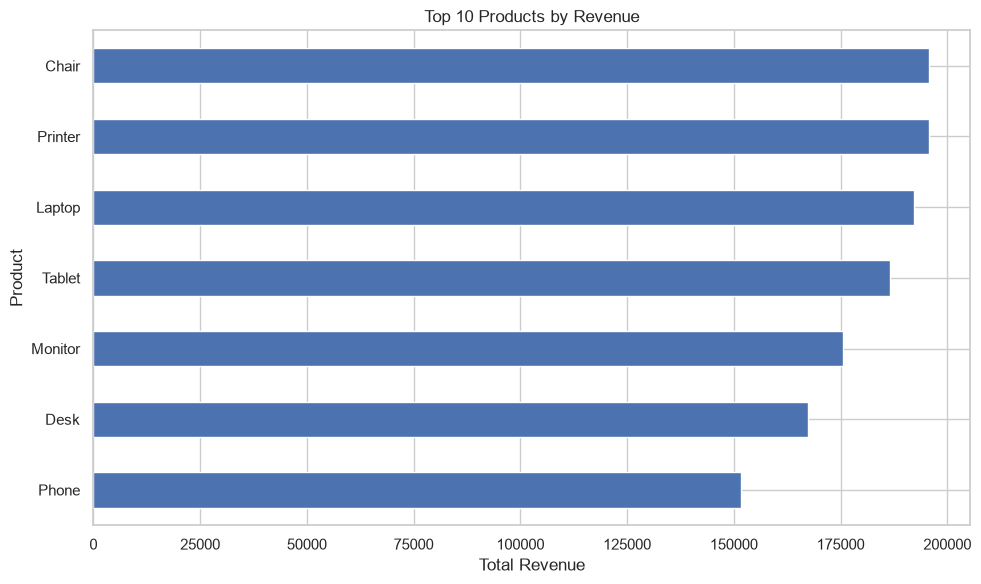

In [5]:
product_revenue = (
    data.groupby("Product")["TotalPrice"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
product_revenue.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

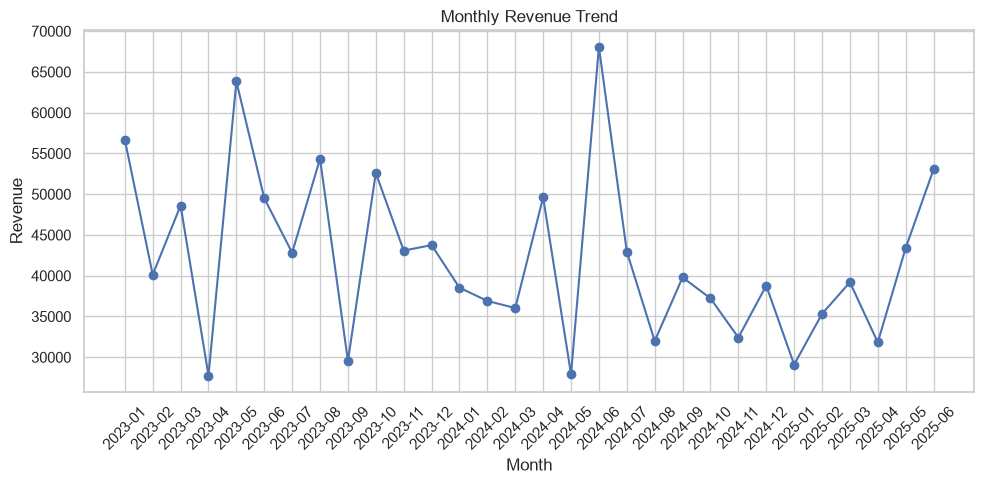

In [6]:
data["Month"] = data["Date"].dt.to_period("M").astype(str)

monthly_revenue = data.groupby("Month")["TotalPrice"].sum()

plt.figure(figsize=(10, 5))
plt.plot(monthly_revenue.index, monthly_revenue.values, marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

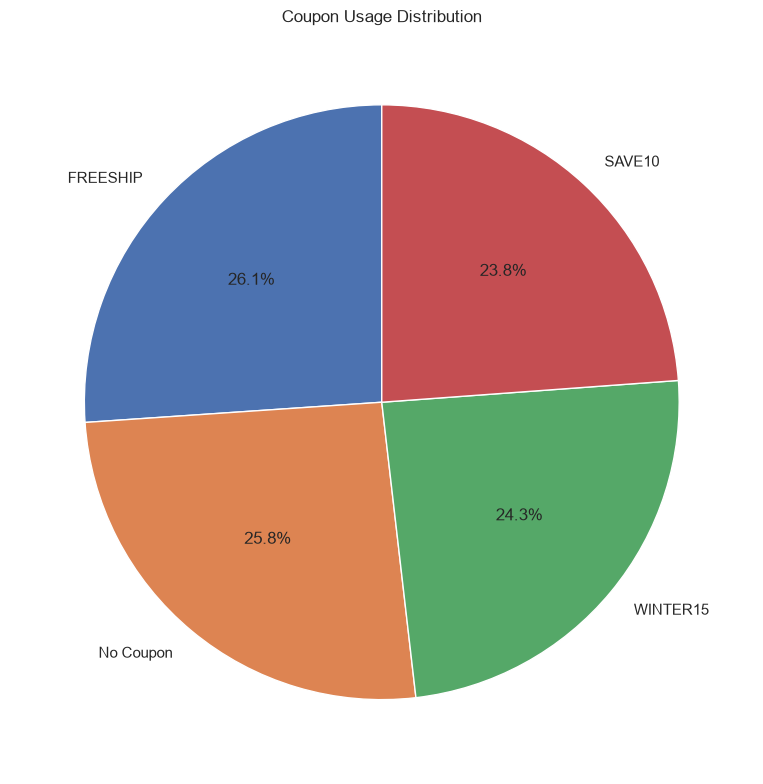

In [7]:
coupon_usage = data["CouponCode"].fillna("No Coupon")
coupon_counts = coupon_usage.value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    coupon_counts.values,
    labels=coupon_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Coupon Usage Distribution")
plt.tight_layout()
plt.show()

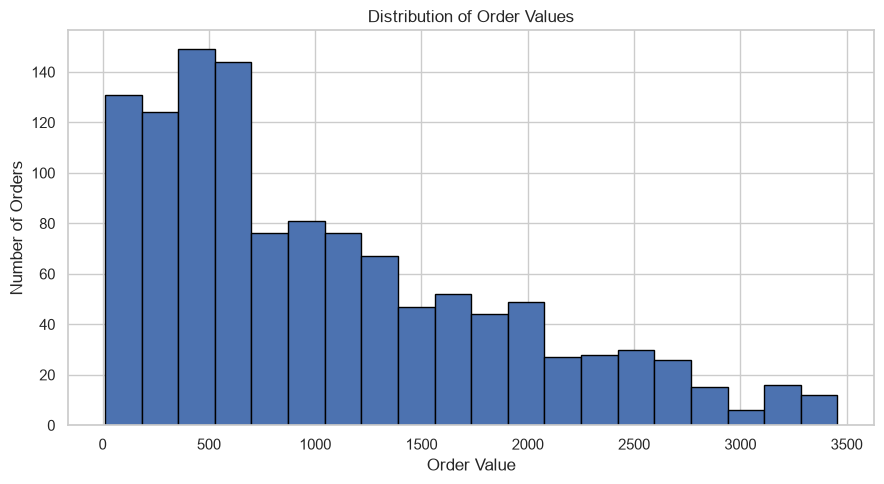

In [8]:
plt.figure(figsize=(9, 5))
plt.hist(data["TotalPrice"], bins=20, edgecolor="black")
plt.title("Distribution of Order Values")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

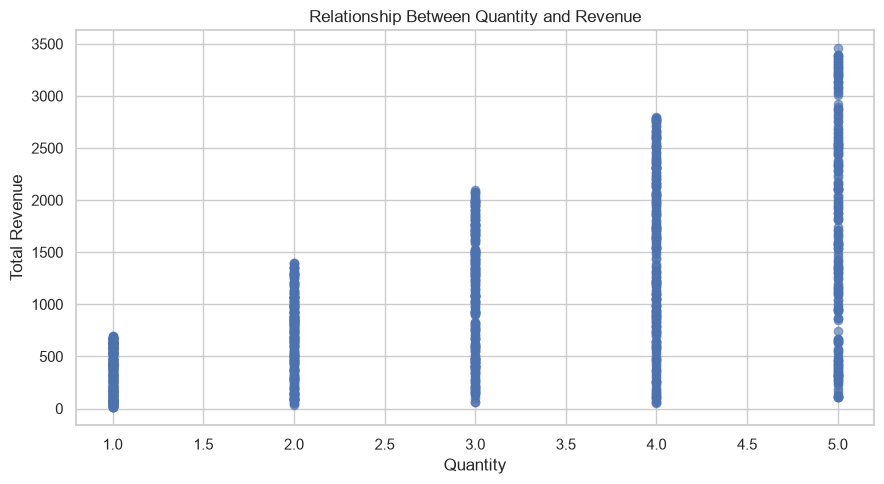

In [9]:
plt.figure(figsize=(9, 5))
plt.scatter(data["Quantity"], data["TotalPrice"], alpha=0.6)
plt.title("Relationship Between Quantity and Revenue")
plt.xlabel("Quantity")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()

In [10]:
print("TOTAL REVENUE:", data["TotalPrice"].sum())
print("TOTAL ORDERS:", data["OrderID"].nunique())
print("TOTAL CUSTOMERS:", data["CustomerID"].nunique())

print("\nTOP 5 PRODUCTS BY REVENUE:")
print(data.groupby("Product")["TotalPrice"].sum()
      .sort_values(ascending=False).head(5))

print("\nMONTH WITH HIGHEST REVENUE:")
print(monthly_revenue.idxmax(), monthly_revenue.max())

print("\nCOUPON USAGE:")
print(coupon_counts)

TOTAL REVENUE: 1264761.96
TOTAL ORDERS: 1200
TOTAL CUSTOMERS: 1189

TOP 5 PRODUCTS BY REVENUE:
Product
Chair      195620.11
Printer    195612.61
Laptop     192126.56
Tablet     186568.95
Monitor    175651.41
Name: TotalPrice, dtype: float64

MONTH WITH HIGHEST REVENUE:
2024-06 68068.54000000001

COUPON USAGE:
CouponCode
FREESHIP     313
No Coupon    309
WINTER15     292
SAVE10       286
Name: count, dtype: int64
